# Healthcare Patient Data Analysis

**Dataset:** `patient_data.csv` — synthetic sample data for educational use.

This notebook cleans patient and appointment records, handles missing values, removes duplicates, creates age groups and BMI categories, and includes embedded visualizations.

> **Privacy:** This dataset is synthetic. It contains no real patient information and is not for clinical use.


## 1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("default")


## 2. Load and inspect data

In [ ]:
df = pd.read_csv("patient_data.csv")
print("Original shape:", df.shape)
display(df.head())
print("\\nMissing values:")
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())


## 3. Remove duplicate records

In [ ]:
df = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df.shape)


## 4. Handle missing values

In [ ]:
for col in ["age", "test_value", "height_m", "weight_kg"]:
    df[col] = df[col].fillna(df[col].median())

print("Missing values after cleaning:")
display(df.isna().sum())


## 5. Create age groups

In [ ]:
age_bins = [0, 12, 19, 35, 60, 120]
age_labels = ["Child (0-12)", "Teen (13-19)", "Young Adult (20-35)",
              "Adult (36-60)", "Senior (61+)"]
df["age_group"] = pd.cut(df["age"], bins=age_bins, labels=age_labels, include_lowest=True)
display(df[["patient_id", "age", "age_group"]].head())


## 6. Calculate BMI and create BMI categories

In [ ]:
df["bmi"] = df["weight_kg"] / (df["height_m"] ** 2)
bmi_bins = [0, 18.5, 25, 30, np.inf]
bmi_labels = ["Underweight", "Normal", "Overweight", "Obese"]
df["bmi_category"] = pd.cut(df["bmi"], bins=bmi_bins, labels=bmi_labels, right=False)
display(df[["patient_id", "bmi", "bmi_category"]].head())


## 7. Patient distribution visualizations
These charts are embedded in the notebook already. Run the cells again to regenerate them.

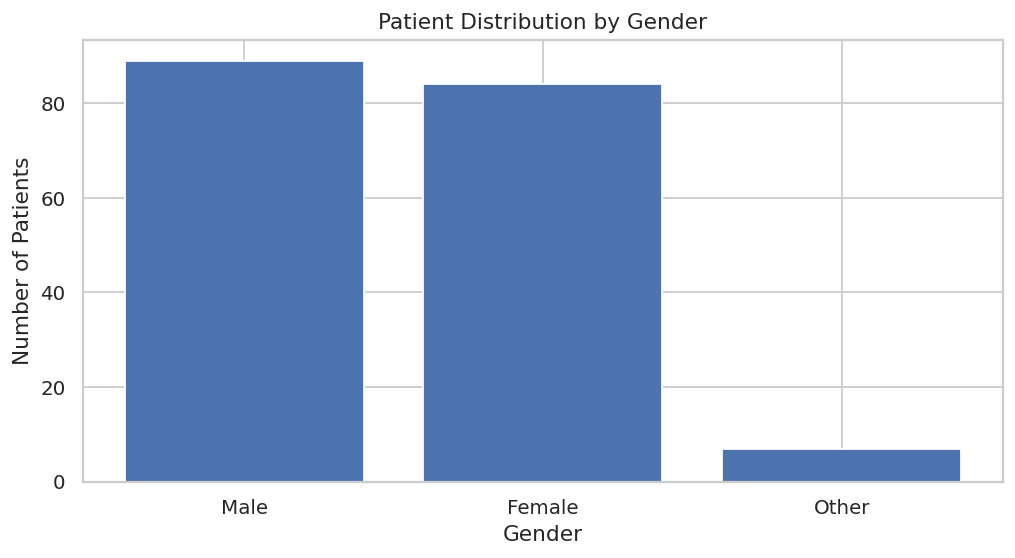

In [ ]:
df["gender"].value_counts().plot(kind="bar", title="Patient Distribution by Gender")
plt.xlabel("Gender"); plt.ylabel("Number of Patients"); plt.tight_layout(); plt.show()


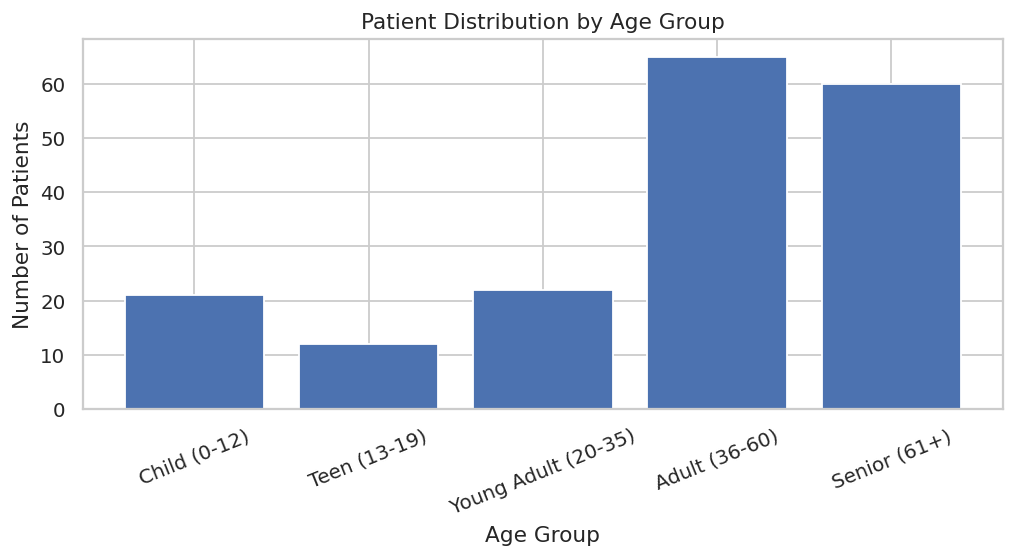

In [ ]:
df["age_group"].value_counts().reindex(age_labels).plot(kind="bar", title="Patient Distribution by Age Group")
plt.xlabel("Age Group"); plt.ylabel("Number of Patients"); plt.xticks(rotation=22, ha="right"); plt.tight_layout(); plt.show()


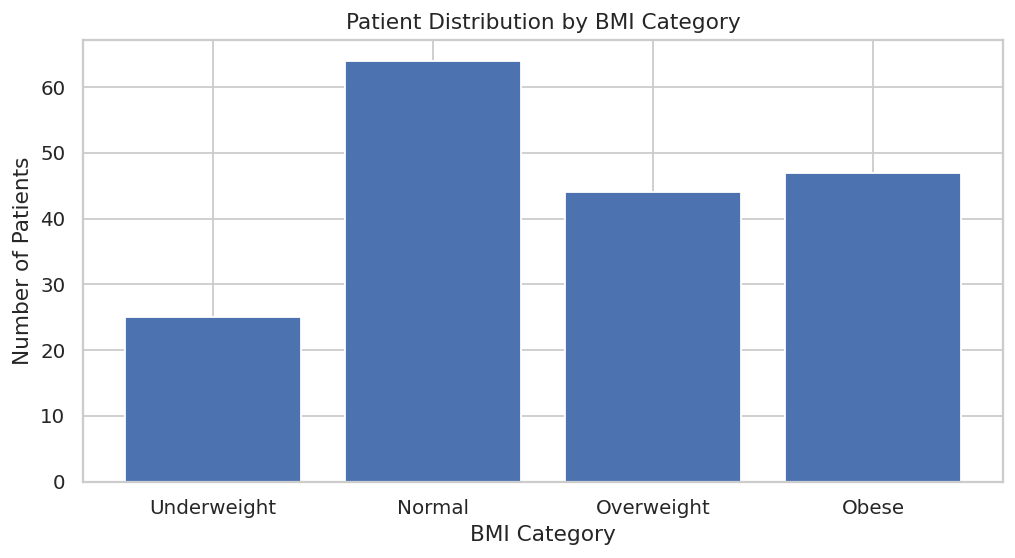

In [ ]:
df["bmi_category"].value_counts().reindex(bmi_labels).plot(kind="bar", title="Patient Distribution by BMI Category")
plt.xlabel("BMI Category"); plt.ylabel("Number of Patients"); plt.tight_layout(); plt.show()


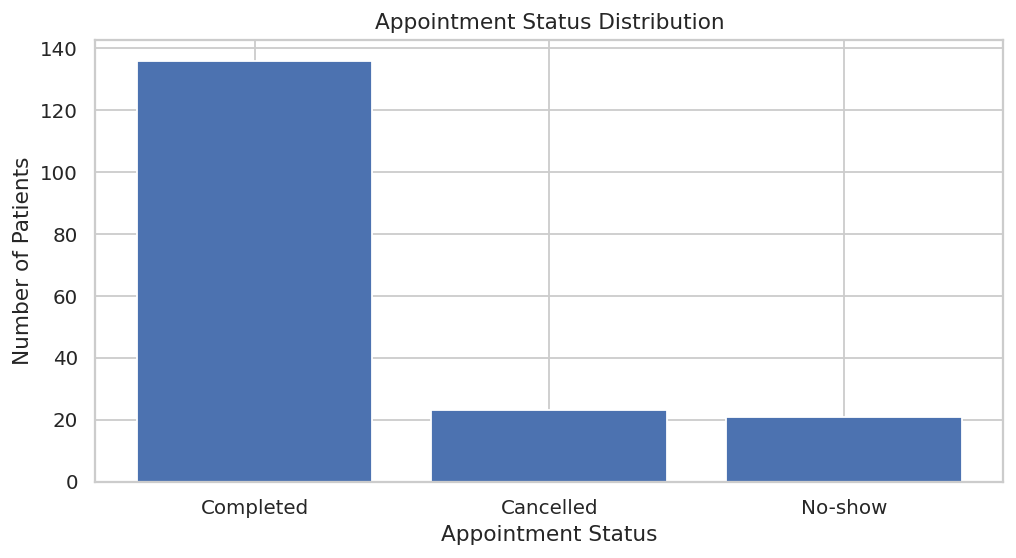

In [ ]:
df["appointment_status"].value_counts().plot(kind="bar", title="Appointment Status Distribution")
plt.xlabel("Appointment Status"); plt.ylabel("Number of Appointments"); plt.tight_layout(); plt.show()


## 8. Summary statistics

In [ ]:
print("Total patient records:", len(df))
print("Average age:", round(df["age"].mean(), 1))
print("Average BMI:", round(df["bmi"].mean(), 1))
print("\\nPatients by age group:")
display(df["age_group"].value_counts().reindex(age_labels))
print("\\nPatients by BMI category:")
display(df["bmi_category"].value_counts().reindex(bmi_labels))
print("\\nAppointments by status:")
display(df["appointment_status"].value_counts())


## 9. Export cleaned dataset

In [ ]:
df.to_csv("cleaned_patient_data.csv", index=False)
print("Cleaned dataset saved as cleaned_patient_data.csv")


## Conclusion

- Missing numeric values were filled using median imputation.
- Exact duplicate rows were removed.
- Age groups and BMI categories were created.
- Four charts visualize gender, age-group, BMI-category, and appointment-status distributions.
- The cleaned dataset is exported as `cleaned_patient_data.csv`.

**Important:** BMI ranges shown are simplified adult descriptive categories and are not appropriate for interpreting children's BMI or making medical decisions. This synthetic dataset is for learning only.
